In [1]:
import pandas as pd
from sqlalchemy import text
import matplotlib.pyplot as plt

from data_access.connection import engine


pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

In [2]:
query = text("""
    SELECT
        i.ID,
        i.Issue_Key,
        i.Project_ID,
        p.Project_Key,
        i.Title,
        i.Description,
        i.Type,
        i.Priority,
        i.Status,
        i.Creation_Date,
        i.In_Progress_Minutes,
        i.Resolution_Date,
        i.Resolution_Time_Minutes
    FROM Issue AS i
    LEFT JOIN Project AS p
        ON p.ID = i.Project_ID
    ORDER BY i.ID
""")

df = pd.read_sql_query(query, engine)

In [3]:
resolved_df = df[
    df["Creation_Date"].notna() 
    &
    df["Resolution_Date"].notna()
]

print("Всего задач:", len(df))
print("Всего закрытых задач:", len(resolved_df))
print("Всего незакрытых задач:", df["Resolution_Date"].isna().sum())

Всего задач: 458232
Всего закрытых задач: 352632
Всего незакрытых задач: 105600


In [4]:
df.shape

(458232, 13)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 458232 entries, 0 to 458231
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   ID                       458232 non-null  int64         
 1   Issue_Key                458232 non-null  str           
 2   Project_ID               458232 non-null  int64         
 3   Project_Key              458232 non-null  str           
 4   Title                    458232 non-null  str           
 5   Description              458232 non-null  str           
 6   Type                     458232 non-null  str           
 7   Priority                 458232 non-null  str           
 8   Status                   458232 non-null  str           
 9   Creation_Date            458232 non-null  datetime64[us]
 10  In_Progress_Minutes      458232 non-null  float64       
 11  Resolution_Date          352632 non-null  datetime64[us]
 12  Resolution_Time_Minutes  45

In [6]:
df.nunique().sort_values()

Priority                       18
Type                           24
Project_Key                    39
Project_ID                     39
Status                         76
In_Progress_Minutes         26416
Resolution_Time_Minutes    197864
Resolution_Date            304906
Title                      412868
Description                421334
Creation_Date              424980
ID                         458232
Issue_Key                  458232
dtype: int64

In [7]:
df.head()

,ID,Issue_Key,Project_ID,Project_Key,Title,Description,Type,Priority,Status,Creation_Date,In_Progress_Minutes,Resolution_Date,Resolution_Time_Minutes
0,65,XD-3768,1,XD,"""How do I make a job restartable in spring xd""","""The jobs that appear under Executions section of Jobs in spring xd admin ui, has restart button...",Bug,Major,To Do,2017-07-10 13:41:25,0.0,NaT,0.0
1,66,XD-3767,1,XD,"""admin config timezone command does not work""","""Working with Spring-XD version 1.3.2.RELEASE Starting the server with {{xd-singlenode}} comman...",Bug,Trivial,To Do,2017-06-26 16:26:27,0.0,NaT,0.0
2,67,XD-3766,1,XD,"""Module Upload command not pushing jar to all containers""","""My project 7 node cluster and in that 2 node are Admin containers and remaining are non admin c...",Bug,Major,To Do,2017-05-19 22:28:43,0.0,NaT,0.0
3,68,XD-3765,1,XD,"""Fix stream failover ""","""See https://github.com/spring-projects/spring-xd/issues/1924""",Story,Minor,Done,2017-03-21 16:54:44,0.0,2017-03-21 16:55:23,0.0
4,69,XD-3764,1,XD,"""SpringXD Job is still executing even after forceful Server shutdown""","""I'm trying to run a Job on SpringXD and the job has 7 steps, When I reach step 4 i'm shutting d...",Bug,Major,To Do,2017-03-06 20:01:41,0.0,NaT,0.0


In [8]:
filtered = df.dropna(subset=["Resolution_Date"])

print(f"{len(filtered)} - Задачи с указанным сроком выполнения")
print(f"{len(df) - len(filtered)} - Задачи без указанного срока выполнения")

352632 - Задачи с указанным сроком выполнения
105600 - Задачи без указанного срока выполнения


In [ ]:
filtered = df[
    (df["Resolution_Date"].isna())
]

filtered

,ID,Issue_Key,Project_ID,Project_Key,Title,Description,Type,Priority,Status,Creation_Date,In_Progress_Minutes,Resolution_Date,Resolution_Time_Minutes
0,65,XD-3768,1,XD,"""How do I make a job restartable in spring xd""","""The jobs that appear under Executions section of Jobs in spring xd admin ui, has restart button...",Bug,Major,To Do,2017-07-10 13:41:25,0.0,NaT,0.0
1,66,XD-3767,1,XD,"""admin config timezone command does not work""","""Working with Spring-XD version 1.3.2.RELEASE Starting the server with {{xd-singlenode}} comman...",Bug,Trivial,To Do,2017-06-26 16:26:27,0.0,NaT,0.0
2,67,XD-3766,1,XD,"""Module Upload command not pushing jar to all containers""","""My project 7 node cluster and in that 2 node are Admin containers and remaining are non admin c...",Bug,Major,To Do,2017-05-19 22:28:43,0.0,NaT,0.0
4,69,XD-3764,1,XD,"""SpringXD Job is still executing even after forceful Server shutdown""","""I'm trying to run a Job on SpringXD and the job has 7 steps, When I reach step 4 i'm shutting d...",Bug,Major,To Do,2017-03-06 20:01:41,0.0,NaT,0.0
5,70,XD-3763,1,XD,"""Duplicate entries in table XD_JOB_REGISTRY""","""Hello, I have encountered following problem while using Spring XD in DIRT (distributed) mode. ...",Bug,Major,To Do,2017-01-23 10:21:08,0.0,NaT,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
457950,508754,SERVER-293,33,SERVER,"""embedded fields don't work with csv export""","""See: http://groups.google.com/group/mongodb-user/browse_thread/thread/d7f1685d006ae4c7""",Bug,Major - P3,Closed,2009-09-13 06:58:28,0.0,NaT,0.0
457976,508780,SERVER-267,33,SERVER,"""Wildcard support in index/query/projection=""","""db.foo.ensureIndex( { """"a.*.b"""" : 1 } ) db.foo.find( { """"a.*.b"""" : 5 } ) db.foo.find( {} , { """"...",Improvement,Major - P3,Open,2009-08-27 00:01:01,0.0,NaT,0.0
458010,508814,SERVER-233,33,SERVER,"""make admin user be able to be authenticated against any db""",,Improvement,Minor - P4,Open,2009-08-12 16:27:51,0.0,NaT,0.0
458087,508891,SERVER-153,33,SERVER,"""javascript sort helper for custom sorting / indexing""",,New Feature,Major - P3,Open,2009-07-13 11:27:33,0.0,NaT,0.0


In [10]:
filtered = df[
    (df["Status"] == "Done") &
    (df["Resolution_Time_Minutes"] < 5.0)
]

print(f"{len(filtered)} - Количество задач, чье время выполнения практически близко к нулю")

1418 - Количество задач, чье время выполнения практически близко к нулю


In [11]:
filtered = df[
    (df["In_Progress_Minutes"] != 0.0)
]

filtered.sample(10)

,ID,Issue_Key,Project_ID,Project_Key,Title,Description,Type,Priority,Status,Creation_Date,In_Progress_Minutes,Resolution_Date,Resolution_Time_Minutes
160669,160738,CONFSERVER-58053,22,CONFSERVER,"""Setting c3p0.min_size to a non-zeroed value causes Confluence to trigger an overhead of Databas...","""h2. Issue Summary Confluence uses [C3P0|https://www.mchange.com/projects/c3p0/] as its datab...",Bug,Medium,Closed,2019-03-19 18:07:09,27585.0,2020-06-30 05:01:52,674514.0
418566,469370,SERVER-42587,33,SERVER,"""Add requires_persistence tag to ttl_with_restart.js test""","""This test verifies that TTL index metadata can be reloaded and be effective after restart. Sinc...",Bug,Major - P3,Closed,2019-08-01 19:03:39,1285.0,2019-08-13 13:41:16,16957.0
100071,100140,JRASERVER-28891,18,JRASERVER,"""Update text on mail setup page""","""{panel:bgColor=#e7f4fa} *NOTE:* This bug report is for *JIRA Server*. Using *JIRA Cloud*? [Se...",Bug,Medium,Closed,2012-07-11 05:51:25,16.0,2012-09-04 02:53:05,79021.0
224246,224315,DM-24003,28,DM,"""Refactor the Autotool Files in ts_rotator_controller""","""This task will reorganize the files in ts_rotator_controller and update the related configurati...",Story,,Done,2020-03-24 22:15:24,3299.0,2020-04-02 18:54:57,12699.0
240555,240624,DM-7435,28,DM,"""Use science exposure filter to find correct coadd in GetCoaddAsTemplateTask""","""{{GetCoaddAsTemplateTask}} does not specify a filter when asking the butler for the correct coa...",Story,,Won't Fix,2016-08-29 19:53:30,313001.0,2019-09-16 19:28:31,1602695.0
346659,397461,TISTUD-7732,13,TISTUD,"""NullPointerException when trying to Configure SDK""","""https://community.appcelerator.com/topic/479/nullpointerexception-when-trying-to-configure-sdk ...",Bug,High,Closed,2015-09-28 03:48:56,74.0,2015-09-28 05:20:13,91.0
418745,469549,SERVER-42406,33,SERVER,"""Provide abstract backtrace support API""","""We have two 'NIX versions of the crash backtracer, one based on libunwind and one based on the ...",New Feature,Major - P3,Closed,2019-07-24 22:13:13,97893.0,2019-11-19 14:43:59,169470.0
254597,254666,JAVA-1559,32,JAVA,"""Explain should set limit to the absolute value of the limit * -1""","""Still investigating why this should be so, but the 2.x Java driver does it, as does the shell.""",Bug,Major - P3,Closed,2014-11-17 20:38:32,1058.0,2014-11-18 22:55:28,1576.0
359854,410658,TIMOB-16231,12,TIMOB,"""LiveView needs to be updated to use the new Titanium CLI 3.2.1 hook API""","""In Titanium CLI 3.2.1, the hooks API changed as apart of TIMOB-16153. The LiveView CLI plugin n...",Bug,Critical,Closed,2014-01-17 22:57:37,4097.0,2014-02-12 18:22:44,37165.0
165669,165738,CONFSERVER-49118,22,CONFSERVER,"""ical4j parsing perfomance""","""{panel:bgColor=#e7f4fa} *NOTE:* This suggestion is for *Confluence Server*. Using *Confluence...",Suggestion,,Closed,2015-08-17 18:23:25,666.0,2015-08-20 03:26:49,3423.0


In [12]:
df.isna()

,ID,Issue_Key,Project_ID,Project_Key,Title,Description,Type,Priority,Status,Creation_Date,In_Progress_Minutes,Resolution_Date,Resolution_Time_Minutes
0,False,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
458227,False,False,False,False,False,False,False,False,False,False,False,False,False
458228,False,False,False,False,False,False,False,False,False,False,False,False,False
458229,False,False,False,False,False,False,False,False,False,False,False,False,False
458230,False,False,False,False,False,False,False,False,False,False,False,False,False


In [13]:
query = text("""
    SELECT
        COALESCE(Priority, 'Не указан') AS Priority,
        COUNT(*) AS Issue_Count,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS Percentage
    FROM Issue
    GROUP BY Priority
    ORDER BY Issue_Count DESC
""")

priority_stats = pd.read_sql_query(query, engine)

priority_stats

,Priority,Issue_Count,Percentage
0,,124073,27.08
1,Low,65819,14.36
2,Major - P3,57146,12.47
3,Medium,56920,12.42
4,Minor,55819,12.18
5,Major,34212,7.47
6,High,24447,5.34
7,Critical,11341,2.47
8,Trivial,6617,1.44
9,Minor - P4,5947,1.30


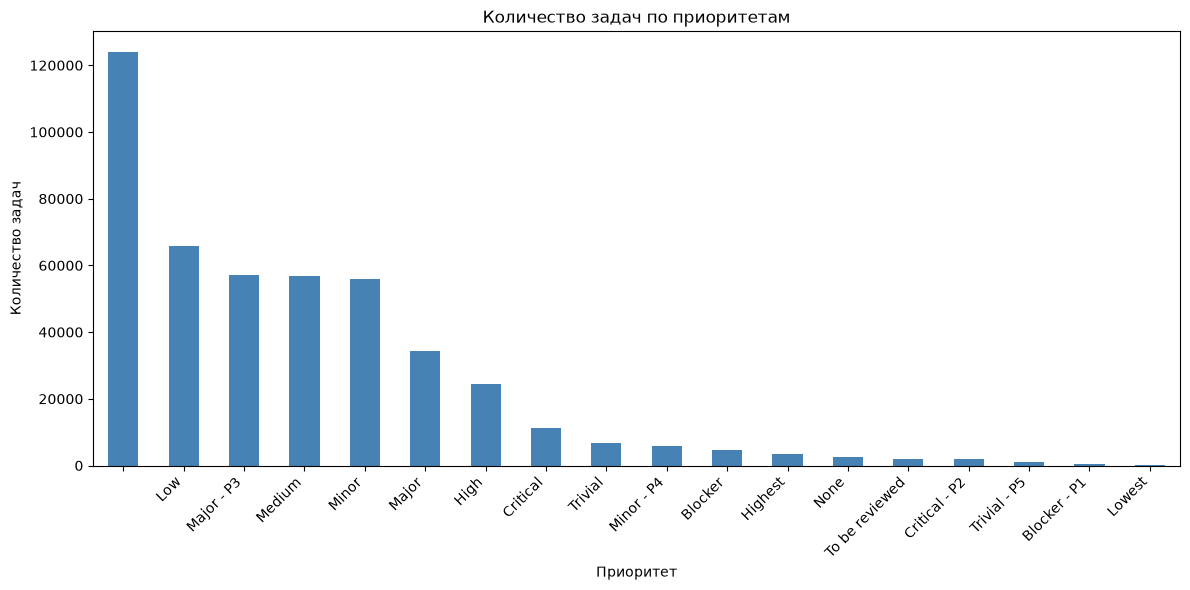

In [14]:
ax = priority_stats.plot.bar(
    x="Priority",
    y="Issue_Count",
    figsize=(12, 6),
    legend=False,
    color="steelblue",
)

ax.set_title("Количество задач по приоритетам")
ax.set_xlabel("Приоритет")
ax.set_ylabel("Количество задач")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
query = text("""
    SELECT
        i.Type AS Type,
        COUNT(*) AS Issue_Count,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS Percentage
    FROM Issue AS i
    GROUP BY Type
    ORDER BY Issue_Count DESC
""")

type_stats = pd.read_sql_query(query, engine)

type_stats

,Type,Issue_Count,Percentage
0,Bug,215570,47.04
1,Suggestion,96370,21.03
2,Improvement,42691,9.32
3,Story,31394,6.85
4,Task,28338,6.18
5,Sub-task,14396,3.14
6,New Feature,14239,3.11
7,Epic,4157,0.91
8,Enhancement Request,3239,0.71
9,Support Request,2368,0.52


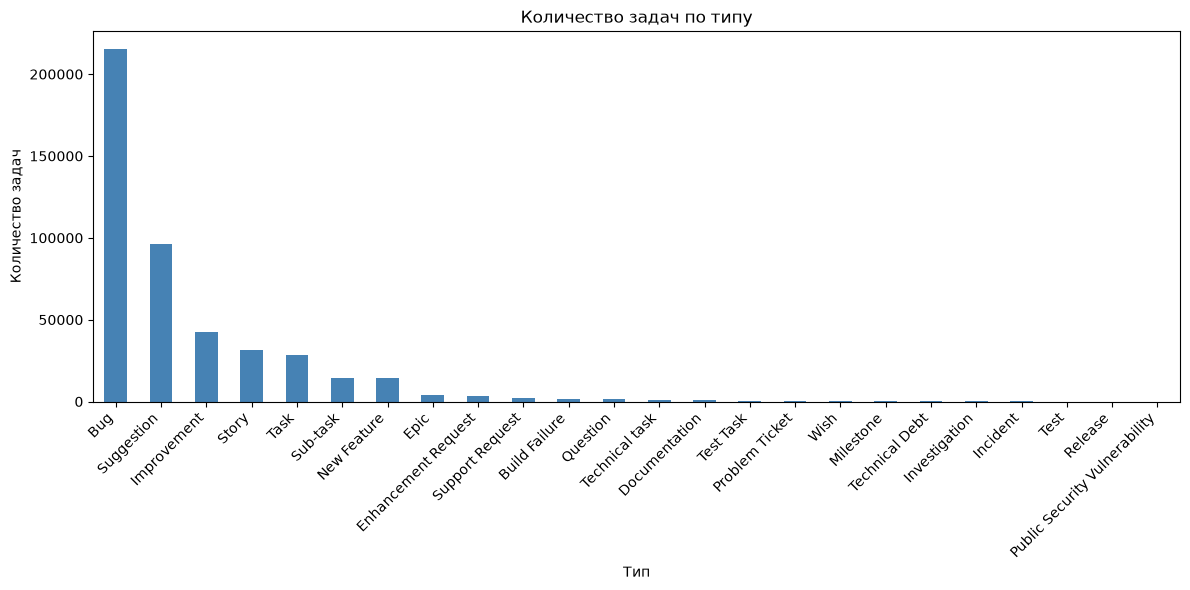

In [16]:
ax = type_stats.plot.bar(
    x="Type",
    y="Issue_Count",
    figsize=(12, 6),
    legend=False,
    color="steelblue"
)

ax.set_title("Количество задач по типу")
ax.set_xlabel("Тип")
ax.set_ylabel("Количество задач")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [17]:
resolved_df[
    ["Creation_Date", "Resolution_Date"]
].dtypes

Creation_Date      datetime64[us]
Resolution_Date    datetime64[us]
dtype: object

In [18]:
before = resolved_df["Resolution_Date"].isna().sum()

resolved_df["Creation_Date"] = pd.to_datetime(
    resolved_df["Creation_Date"],
    errors="coerce",
)

resolved_df["Resolution_Date"] = pd.to_datetime(
    resolved_df["Resolution_Date"],
    errors="coerce",
)

after = resolved_df["Resolution_Date"].isna().sum()

print("Количество некорректных дат:", after - before)

resolved_df["Duration_Days"] = (
    resolved_df["Resolution_Date"]
    - resolved_df["Creation_Date"]
).dt.total_seconds() / 86_400

Количество некорректных дат: 0


In [19]:
resolved_df["Resolution_Time_Days"] = resolved_df["Resolution_Time_Minutes"] / 1440

resolved_df["Duration_Difference"] = resolved_df["Duration_Days"] - resolved_df["Resolution_Time_Days"]

In [20]:
resolved_df

,ID,Issue_Key,Project_ID,Project_Key,Title,Description,Type,Priority,Status,Creation_Date,In_Progress_Minutes,Resolution_Date,Resolution_Time_Minutes,Duration_Days,Resolution_Time_Days,Duration_Difference
3,68,XD-3765,1,XD,"""Fix stream failover ""","""See https://github.com/spring-projects/spring-xd/issues/1924""",Story,Minor,Done,2017-03-21 16:54:44,0.0,2017-03-21 16:55:23,0.0,0.000451,0.000000,0.000451
20,85,XD-3748,1,XD,"""Unable to register the JMX bean MessageHistory from Spring Integration""","""If I try to use <int:message-history/> when developing a Spring XD module, it fails when try to...",Bug,Minor,Done,2016-02-24 10:51:02,87.0,2016-12-23 14:49:45,436558.0,303.165775,303.165278,0.000498
21,86,XD-3747,1,XD,"""Rabbit Bus: Expose ChannelCacheSize on CachingConnectionFactory""","""http://stackoverflow.com/questions/35563064/processing-messages-through-namedchannels-with-pref...",Improvement,Minor,Done,2016-02-23 18:31:38,2.0,2016-12-23 14:49:26,437537.0,303.845694,303.845139,0.000556
22,87,XD-3746,1,XD,"""Update Spring Framework to 4.2.4""",,Improvement,Minor,Done,2016-02-23 18:18:48,0.0,2016-02-23 18:19:07,0.0,0.000220,0.000000,0.000220
23,88,XD-3745,1,XD,"""Update Spring-AMQP to 3.6, RabbitMQ Client to 1.5.4""","""Update to amqp-client 3.6.0 and spring-amqp 1.5.4""",Improvement,Minor,Done,2016-02-23 18:04:09,0.0,2016-02-23 18:04:42,0.0,0.000382,0.000000,0.000382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
458227,509031,SERVER-5,33,SERVER,"""file configuration""",""" make mongod use boost argument handling so can read frmo file""",Improvement,Minor - P4,Closed,2009-04-09 09:15:20,0.0,2009-07-14 16:27:28,138672.0,96.300093,96.300000,0.000093
458228,509032,SERVER-4,33,SERVER,"""assure stack size per thread isn't too big""","""we might have hundreds or thousands of clients connected -- in which case it would waste a lot ...",Improvement,Minor - P4,Closed,2009-04-09 09:14:27,0.0,2010-02-25 21:42:33,464428.0,322.519514,322.519444,0.000069
458229,509033,SERVER-3,33,SERVER,"""implement inf. loop protection in spider monkey""","""need to make inf. loop protection configurable. may hold off on this until decide on javascript...",Improvement,Minor - P4,Closed,2009-04-09 09:02:06,0.0,2009-05-27 14:08:21,69426.0,48.212674,48.212500,0.000174
458230,509034,SERVER-2,33,SERVER,"""inf. loop protection for $where and dbEval""",,Improvement,Major - P3,Closed,2009-04-09 08:59:26,0.0,2009-08-25 11:29:57,198870.0,138.104525,138.104167,0.000359


In [21]:
import numpy as np


matches = np.isclose(
    resolved_df["Duration_Days"],
    resolved_df["Resolution_Time_Days"],
    atol=1 / 1440,
    rtol=0,
)

pd.Series(matches).value_counts()

True     277288
False     75344
Name: count, dtype: int64

In [22]:
query = text("""
    SELECT
        i.ID,
        i.Issue_Key,
    	COUNT(i.Issue_Key) AS status_change_counts
    FROM Issue AS i
    LEFT JOIN Change_Log AS cl
    	ON cl.Issue_ID = i.ID
    WHERE LOWER(cl.Change_Type) = 'status' AND i.Resolution_Date IS NOT NULL
    GROUP BY i.Issue_Key, i.ID
    ORDER BY i.ID
""")

change_log_status_df = pd.read_sql_query(query, engine)

print("Количество задач, где изменялся статус:", len(change_log_status_df))

change_log_status_df

Количество задач, где изменялся статус: 352632


,ID,Issue_Key,status_change_counts
0,68,XD-3765,2
1,85,XD-3748,9
2,86,XD-3747,9
3,87,XD-3746,4
4,88,XD-3745,4
...,...,...,...
352627,509031,SERVER-5,3
352628,509032,SERVER-4,3
352629,509033,SERVER-3,3
352630,509034,SERVER-2,2


In [23]:
query = text("""
    SELECT Change_Type, COUNT(Change_Type) AS Count_Changes FROM Change_Log
    GROUP BY Change_Type
""")

change_type_count_df = pd.read_sql_query(query, engine)

change_type_count_df

,Change_Type,Count_Changes
0,OTHER,6726893
1,STATUS,1779677
2,DESCRIPTION,348103
3,PEOPLE,349551
4,STORY_POINT,49195


In [24]:
query1 = text("""
    SELECT
        COUNT(*) AS Priority_Changes,
        COUNT(DISTINCT Issue_ID) AS Issues_With_Priority_Changes
    FROM Change_Log
    WHERE LOWER(Field) = 'priority';
""")

query2 = text("""
    SELECT
    	COUNT(*) AS Priority_Changes,
    	COUNT(DISTINCT cl.Issue_ID) AS Issues_With_Priority_Changes
    FROM Issue AS i
    JOIN Change_Log AS cl
    	ON i.ID = cl.Issue_ID
    WHERE LOWER(cl.Field) = 'priority' AND i.Resolution_Date IS NOT NULL
""")

priority_changes = pd.read_sql_query(query2, engine)

priority_changes

,Priority_Changes,Issues_With_Priority_Changes
0,96227,83986


In [25]:
query = text("""
    SELECT
        i.Issue_Key,
        cl.Creation_Date,
        cl.From_String AS Previous_Priority,
        cl.To_String AS New_Priority
    FROM Change_Log AS cl
    JOIN Issue AS i
        ON i.ID = cl.Issue_ID
    WHERE LOWER(cl.Field) = 'priority'
    ORDER BY cl.Creation_Date
    LIMIT 100;
""")

priority_changes_df = pd.read_sql_query(query, engine)

priority_changes_df.sample(10)

,Issue_Key,Creation_Date,Previous_Priority,New_Priority
18,JRASERVER-22,2002-02-11 06:46:00,,Major
54,JRASERVER-3657,2004-04-29 07:02:33,Blocker,Major
73,JRASERVER-3549,2004-06-07 01:50:16,Major,Minor
93,CONFSERVER-1560,2004-07-19 01:27:03,Major,Minor
59,JRASERVER-3716,2004-05-11 02:04:06,Minor,Trivial
41,CONFSERVER-870,2004-03-02 22:54:17,Blocker,Major
51,JRASERVER-3585,2004-04-19 01:06:13,Critical,Minor
1,JRASERVER-4,2002-02-08 04:46:00,,Minor
46,JRASERVER-3420,2004-03-22 04:51:31,Critical,Major
88,JRASERVER-3143,2004-07-02 04:41:53,Major,Minor
